# Homework10

Exercises to practice dimensionality reduction with PCA

## Goals

- Add unsupervised pre-processing to our ML flow: encode -> normalize -> pre-process -> train -> evaluate
- Build an intuition for PCA and when/how to use it
- Understand the benefits of dimensionality reduction

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [78]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/Homework08/raw/main/Homework08_utils.pyc" -O Homework08_utils.pyc

!wget -qO- "https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/0801-500.tar.gz" | tar xz

In [79]:
from os import listdir, path
from PIL import Image as PImage

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

from image_utils import get_pixels, make_image

from Homework08_utils import CamUtils

## PCA and Classification

Let's practice doing some more image classification with `PCA` and analyzing the results.

The dataset is the same one we used in `Homework08`. It has images from $25$ different security cameras, and our task is to separate them by camera. Some of the cameras move, some of them don't, and there are more than $1000$ images, so there's no way we want to do this by hand.

Let's start by loading the training images into a list of pixels, like we did with the `faces` dataset in class.

### Loading Data

If we look at the images in `./data/image/0801-500/train/`, we'll notice that they are named and organized in a slightly different way. They're all in the same directory and the first part of their filename specifies which camera they came from. Even though those `ids` are numbers, they're not sequential, so we'll use some helper functions to extract a unique `label` from their filenames.

This is exactly what the `OrdinalEncoder` class does, but since we only have to encode this one column, we'll do it by hand while we read the files in.

In [80]:
# this creates a list of all the files in a given directory, that end in .jpg
train_files = [f for f in listdir("./data/image/0801-500/train") if f.endswith(".jpg")]

In [81]:
# TODO: check and see what is inside the list here
train_files[:5]  # show the first 5 files in the list

['03-05.jpg', '28-69.jpg', '26-50.jpg', '07-75.jpg', '23-60.jpg']

Now we'll read the image pixels and extract their labels. `CamUtils.get_label()` is the helper function we'll use to "encode" and return a label id based on the filename.

In [82]:
pixel_data = []
label_data = []

for fname in train_files:
  label = CamUtils.get_label(fname)
  img = PImage.open(path.join("./data/image/0801-500/train", fname))
  pixel_data.append(get_pixels(img))
  label_data.append(label)

In [83]:
# TODO: check if labels got extracted correctly by looking at 
#       the first few items of the label list and the filename list
label_data[:5], train_files[:5] 

([2, 23, 21, 5, 18],
 ['03-05.jpg', '28-69.jpg', '26-50.jpg', '07-75.jpg', '23-60.jpg'])

Like in `Homework08`, the labels and the filenames won't match exactly since labels start at $0$ and the filenames start at $01$ and skip some numbers.

We can open some images from pixels, just to make sure we loaded them correctly:

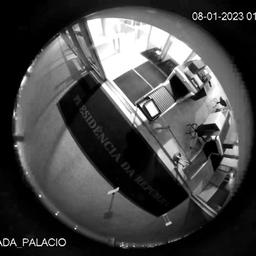

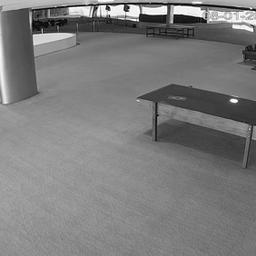

In [84]:
display(make_image(pixel_data[0]))
display(make_image(pixel_data[10]))

### PCA

Create a `DataFrame` called `cam_pca_df` by running `PCA` on the list of pixel data, just like we did in class, and then append a `label` column to it, just like we did in `Homework08` with: `train_df["label"] = label_data`.

You can change how many components to extract from the images later, but for this first run just use $10$ components so we can compare classification with $10$ `PCA` components to the classification with $10$ random features from `Homework08`.  Make sure to confirm how much of the `variance` is preserved by this transformation.

0.7852542513741757
[[-15175.50014447   -218.50003659   2079.64783156  -8805.12050804
   10356.77888109   2842.02135374   -898.30459235   1276.41381464
   -2261.8002651    -685.62957293]
 [  9125.14362638  -2757.95626108   1513.73674839  -1653.92995341
   -3465.05056399   1121.50597813  -1399.54244793    740.59937421
     844.43718917   -534.4687883 ]
 [  1607.56781015   -374.75192755   3798.24302701   3831.1043694
   -1028.04418531    590.137531    -2516.35484873  -4317.06688871
     465.67404488   -141.90781127]
 [  8649.19743951  -6626.16147279   3316.2829133   -3755.65451987
   -2167.12731948    426.6735407   -3197.21169249   5857.84834607
    1383.41966811  -3279.75706356]
 [  1504.55897389  -6677.50345567  -3184.9174547    8828.28935368
    1700.7753712    6255.20879268   3707.70373108  -1655.66706752
   -1586.22521818  -2858.80702692]]
[2, 23, 21, 5, 18]


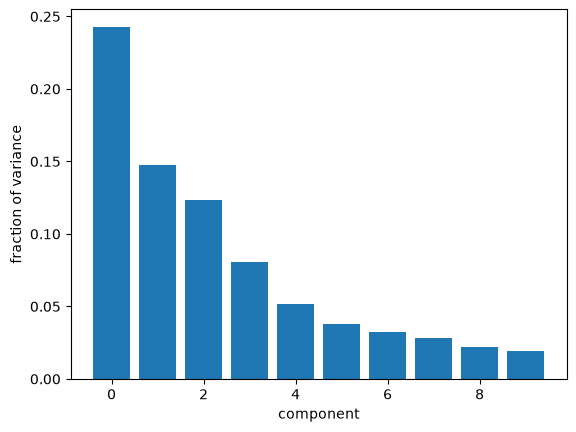

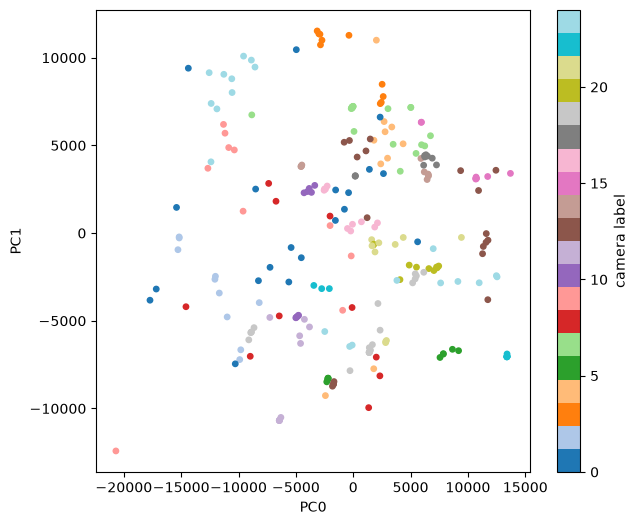

In [85]:
from data_utils import toDataFrame

# TODO: 
compononet_num = 10
# run PCA, get DataFrame
pca = PCA(n_components=compononet_num)
pca.fit(pixel_data)

cam_pca = pca.transform(pixel_data)    # rows = images, columns = PC0..PC9
cam_pca_df = toDataFrame(pca.transform(pixel_data))
cam_pca_df.columns = [f"PC{i}" for i in range(compononet_num)]
cam_pca_df["label"] = label_data

# TODO: add "label" column
 
# TODO: print variance
print(sum(pca.explained_variance_ratio_))

# TODO: take a look at the first 5 rows
print(cam_pca[:5])
print(label_data[:5])



import matplotlib.pyplot as plt

plt.bar(range(compononet_num), pca.explained_variance_ratio_)
plt.xlabel("component")
plt.ylabel("fraction of variance")
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(cam_pca[:, 0], cam_pca[:, 1], c=label_data, cmap="tab20", s=15)
plt.xlabel("PC0")
plt.ylabel("PC1")
plt.colorbar(label="camera label")
plt.show()



### Interpretation

<span style="color:hotpink">
How many components did you keep ?<br>
Did you try different numbers ?<br>
What percent of variance is kept by this transformation?
</span>

<span style="color:hotpink;">at n=5, 64%b of the variance explained, at 10 it's closer to 78%.  I think an n=6 looks ok, but I'm honestly unsure of how to make a clear call here. </span>
<p> edit: after looking at image 10, I brought the n up to 20, at 10 it was unrecognizable</p>

### Reconstruct

Before we go run our classification, let's take a look at some reconstructed images, just to make sure they make sense.

Take a look at reconstructed versions of images $0$, $10$, and whichever other images you might have opened above.

We did this in class. It involves a `inverse_transform()` function.

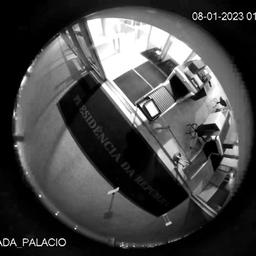

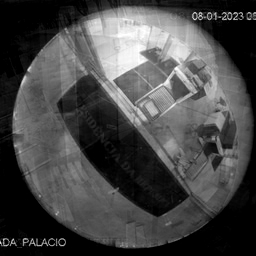

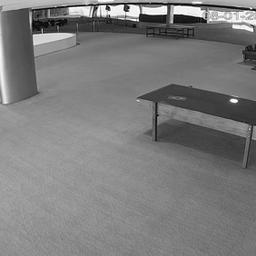

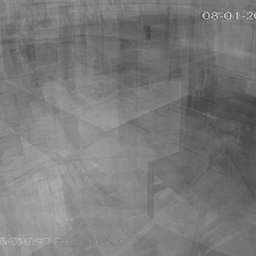

In [86]:
# TODO: reconstruct image at index 0

display(make_image(pixel_data[0]))
display(make_image(pca.inverse_transform(cam_pca[0:1])[0]))

# TODO: reconstruct image at index 10

display(make_image(pixel_data[10]))
display(make_image(pca.inverse_transform(cam_pca[10:11])[0]))

    # image 10


The reconstructed images should look blurrier and noisier than the original ones, but they should still look something like the original ones.

### Classify !

Train a `RandomForestClassifier` on the `PCA` data.

Remember to separate the output feature (`label`) from the input features (`PC0`, `PC1`, etc).

In [87]:
# TODO: create a classifier
X = cam_pca_df.drop(columns="label")   # PC0, PC1, ... PC9
y = cam_pca_df["label"]                # the labels

clf = RandomForestClassifier(random_state=0)
clf.fit(X, y)
train_predictions = clf.predict(X)

# TODO: split input and output features
# TODO: fit the model

# TODO: run predictions
CamUtils.classification_accuracy(train_files, train_predictions)


1.0

### Measure Error

For the train set we could use the generic `classification_error()` function that we've used before because we have the true labels for each file, but for measuring accuracy for our `test` set classification, which has secret labels, we have to use a more specific function from the `CamUtils` class.

The function is called `classification_accuracy()` and it takes $2$ parameters, a list of filenames and the predicted labels associated with those filenames.

The result is an accuracy score ratio, between $0.0$ and $1.0$.

We can run this function on the `train` set as well:

In [88]:
# train_files is the list of files we got way up above
CamUtils.classification_accuracy(train_files, train_predictions)

1.0

### Interpretation

<span style="color:hotpink">
What does this mean?<br>
Should we expect the same result from the test dataset?<br>
Why, or why not?
</span>

<span style="color:hotpink;">It's a perfect classification because the classification schema is based on the data evaluated. The number should drop when used on test data. </span>

### Run on Test set

Now we'll open the image files inside the `./data/image/0801-500/test/` directory, using almost the exact same steps as we did above to create a `DataFrame` with the exception that we don't have labels for these images.

In [89]:
# TODO: create a list of files in the test/ directory
test_files = []
test_files = [f for f in listdir("./data/image/0801-500/test") if f.endswith(".jpg")]
# TODO: check its length and content
print(len(test_files))
print(test_files[:5])

1573
['7446006.jpg', '6844827.jpg', '14590409.jpg', '7330491.jpg', '8569853.jpg']


We'll use a similar loop to extract the pixel information from these images, except we don't have `label` data, just pixels.

In [90]:
test_pixel_data = []

for fname in test_files:
  img = PImage.open(path.join("./data/image/0801-500/test", fname))
  test_pixel_data.append(get_pixels(img))

Now we can run `PCA` and the `RandomForestClassifier`.

Since those are already trained, all we have to do is run their `transform()` function on the data.

In [95]:
test_pca = pca.transform(test_pixel_data)
test_pca_df = toDataFrame(test_pca)
test_pca_df.columns = [f"PC{i}" for i in range(compononet_num)]

test_pca_df.head()
# TODO: run PCA on test pixels, get DataFrame
#       this is the same PCA that was created above, not a new one



,PC0,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,10481.564075,253.723303,5004.087916,3638.023645,4009.102375,-1005.169866,-466.903124,1013.131165,-408.527165,-417.575440
1,4995.015983,7145.028844,-7493.698666,819.325790,4250.418204,-1226.817696,-511.241062,592.934420,-2910.100929,1866.939811
2,12539.093086,-2438.443554,-378.829071,-1746.847848,-3081.372925,1205.217919,-1122.187667,2053.584346,20.470594,-390.402942
3,5057.106390,7190.487814,-7479.802106,836.755320,4238.943578,-1219.935653,-512.615879,604.600856,-2896.330392,1870.749980
4,13424.395274,-7025.440578,-5458.221197,-1007.384670,951.559959,297.585930,-977.466445,-1263.056525,-1213.914428,2343.745519


It's always a good idea to check the result of the `PCA` transformation by looking at the `DataFrame` and reconstructing some images.

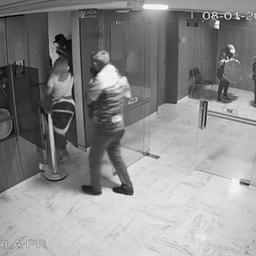

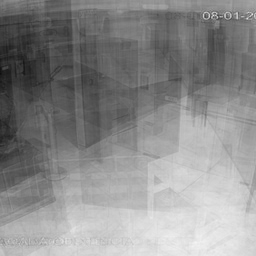

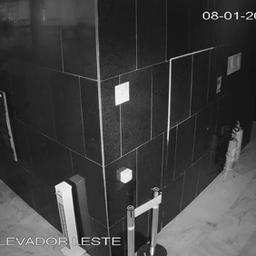

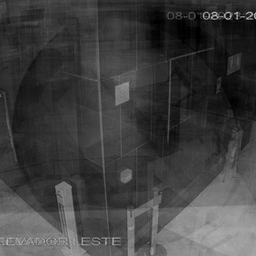

In [92]:
display(make_image(test_pixel_data[0]))
display(make_image(pca.inverse_transform(test_pca[0:1])[0]))

display(make_image(test_pixel_data[10]))
display(make_image(pca.inverse_transform(test_pca[10:11])[0]))

### Interpretation

<span style="color:hotpink"><br>
The reconstructed images from the `test` set will always be noisier than the `train` images.<br><br>
Why?<br><br>
</span>

<span style="color:hotpink;">Because the fit is based on the training data, it'll always be slightly less accurate on new data</span>



Run the classifier and get predicted labels. Then get its accuracy ratio is by running the `CamUtils.classification_accuracy()` function with the list of filenames and list of predictions.

In [97]:
test_predictions = clf.predict(test_pca_df)
CamUtils.classification_accuracy(test_files, test_predictions)


0.9256198347107438

### Interpretation

<span style="color:hotpink">
What's the accuracy ? How could we improve that if we wanted ?<br>
How does this compare to the classification model from <code>Homework08</code>? They can both be tuned to perform well, but how many features did we need last time in order to get an accuracy comparable to this?
</span>

<span style="color:lavender;">HW 8 made predictions based on raw pixel data and maxed out accuracy at around 66%. Here the clustering gets us up to more than 90%. Clustering shows an obvious advantage. Computers are better at figuring our what's salient to them than humans are. Forcing a program to classify based on what a human thinks is a category may be hindering it.</span>